# 2.21 · Variational inference and normalizing flows: inference as optimisation

**Before this:** [2.10](2-10_loss_functions_optimisation.ipynb) (loss functions and Adam), [2.17](2-17_jax_differentiable.ipynb) (autodiff), [2.18](2-18_gradients_hmc_nuts.ipynb) (NUTS, for comparison). Optional notebook.
**You will be able to:** explain the ELBO and why maximising it fits a distribution to the posterior; use the
reparameterisation trick; choose between mean-field, full-rank and flow families and predict what each can miss;
recognise mode seeking and under-dispersion; check a VI answer against a sampler.
**Optional sections:** 2 (reparameterisation details).

NUTS (2.18), SMC (2.20) and the ensemble methods (2.24, 2.26) all produce a crowd of samples. Variational inference (VI)
does something different: it picks a family of simple distributions, then *optimises* the member of that family that
is closest to the posterior. Inference becomes a loss function and an optimiser (2.10), which is fast and needs only
gradients. The price is that the answer can never be better than the family, and the usual notion of "closest"
tends to hide inside one part of the posterior rather than cover all of it (2.28). This notebook measures both,
on shapes where the exact posterior is known and on a one-patch afterslip model (the forward model used in topic 3).

**Words this notebook defines:** variational family, ELBO, evidence (log Z), reparameterisation trick, Monte Carlo
gradient, mean field, full rank, normalizing flow, change of variables, inverse autoregressive flow (IAF), block
neural autoregressive flow (BNAF), mode seeking, under-dispersion, non-identifiable direction, amortised inference.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| tilted double well (sections 1, 2) | 1 | (a given unnormalised density) | none: $\ln\tilde p(m) = -2.5(m^2-1)^2 - 0.6m$ | n/a |
| correlated, banana, two modes, funnel (sections 3, 4) | 2 | 1 to 2 | the test shapes of 2.15 | linear / nonlinear / no forward model (funnel) |
| afterslip on one patch, Δτ known (section 5) | $\ln a\sigma$, $\ln v_0$ | GPS at 23 epochs in the first 30 days, σ = 2 mm | exact solution of $\dot\tau = -k\,2v_0\sinh(\tau/a\sigma)$ | nonlinear |
| the same with Δτ unknown (section 6) | $\ln a\sigma$, $\ln v_0$, $\Delta\tau$ | the same 23 epochs | the same | nonlinear, with a direction the data cannot resolve |

Background references (cited by author and year): Kingma & Welling 2014 (reparameterisation), Rezende &
Mohamed 2015 (normalizing flows), Kingma et al. 2016 (IAF), De Cao, Aziz & Titov 2019 (BNAF), Kucukelbir et al.
2017 (automatic VI, which NumPyro's autoguides follow), Blei, Kucukelbir & McAuliffe 2017 (review).

In [1]:
import sys, pathlib, time, inspect
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpyro
numpyro.set_host_device_count(4)                 # 4 NUTS chains in parallel (before any JAX computation)
import numpyro.distributions as dist
from numpyro.distributions import constraints
from numpyro.infer import SVI, Trace_ELBO, MCMC, NUTS
from numpyro.infer.autoguide import AutoDiagonalNormal, AutoMultivariateNormal, AutoIAFNormal, AutoBNAFNormal
from numpyro.optim import Adam
import jax, jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S
from bayeskit import afterslip as AS

T0 = time.time()
VI = "#b03a74"                                   # variational approximations (all families; columns name the family)
NU = S.COLORS["nuts"]                            # NUTS, blue as everywhere
print("numpyro", numpyro.__version__, "| jax", jax.__version__)

numpyro 0.21.0 | jax 0.10.0


## 1. Inference as optimisation: the ELBO

**In plain words.** Choose a family of simple shapes, for example every bell curve. Slide and stretch the bell until
it overlaps the posterior as well as possible, then use the bell as the answer. "As well as possible" needs a score
that can be computed without knowing the posterior's normalising constant (the evidence, 2.20 section 9; 2.29). That
score is the ELBO, and climbing it is the same as shrinking the KL divergence between the bell and the posterior.

**The KL divergence in brief** (2.28 develops it fully). $D_{\mathrm{KL}}(q\,\|\,p) = \mathbb E_q[\ln q - \ln p]$: draw
points from $q$ and average how much more probable each one is under $q$ than under $p$, in log units. It is zero only
when $q = p$ and positive otherwise. It is not symmetric: $D_{\mathrm{KL}}(q\|p)$ punishes $q$ heavily for putting
mass where $p$ has almost none, and hardly at all for leaving parts of $p$ uncovered. That asymmetry is why VI tends
to sit inside one part of a posterior (**mode seeking**) instead of spreading over all of it.

**Precisely.** For a family $q_\phi(\mathbf m)$ and an unnormalised posterior $\tilde p(\mathbf m) =
p(\mathbf d\mid\mathbf m)\,p(\mathbf m)$ with $Z = \int\tilde p$,

$$\mathrm{ELBO}(\phi) = \mathbb E_{q_\phi}\big[\ln\tilde p(\mathbf m)\big] - \mathbb E_{q_\phi}\big[\ln q_\phi(\mathbf m)\big]
= \ln Z - D_{\mathrm{KL}}\big(q_\phi\,\|\,p(\cdot\mid\mathbf d)\big) \le \ln Z .$$

The second term is the **entropy** of $q$, the average of $-\ln q$ under $q$, which measures how spread out $q$ is
(2.27; for a Gaussian $\tfrac12\ln(2\pi e s^2)$ per dimension). The loss NumPyro
minimises (`Trace_ELBO`) is $-\mathrm{ELBO}$. The KL here is $D_{\mathrm{KL}}(q\,\|\,p)$, the mode-seeking direction of 2.28.

The test density is a tilted double well, $\ln\tilde p(m) = -2.5(m^2-1)^2 - 0.6m$: two bumps near $\pm1$, the left
one heavier. Its $Z$ is not known in closed form; we compute it by quadrature to check the identity.

In [2]:
logp1 = lambda m: -2.5 * (m ** 2 - 1) ** 2 - 0.6 * m
mg = np.linspace(-4, 4, 40001)
dm = mg[1] - mg[0]
p_tilde = np.exp(logp1(mg))
logZ = np.log(p_tilde.sum() * dm)
p1 = p_tilde / np.exp(logZ)
gh_x, gh_w = np.polynomial.hermite_e.hermegauss(80)          # Gauss-Hermite nodes for E over N(0, 1)
gh_w = gh_w / gh_w.sum()


def elbo_exact(mu, log_s):
    """ELBO of q = N(mu, s^2) by quadrature (no Monte Carlo noise)."""
    s = np.exp(log_s)
    return float(np.sum(gh_w * logp1(mu + s * gh_x)) + 0.5 * np.log(2 * np.pi * np.e * s ** 2))


def elbo_hat(phi, eps):
    """Monte Carlo ELBO with the reparameterisation m = mu + s * eps (eps ~ N(0, 1) does not depend on phi)."""
    mu, s = phi[0], jnp.exp(phi[1])
    m = mu + s * eps
    return jnp.mean(logp1(m)) + 0.5 * jnp.log(2 * jnp.pi * jnp.e * s ** 2)


grad_hat = jax.jit(jax.grad(elbo_hat))


def fit_1d(phi0, K=8, n=600, lr=0.03, seed=0):
    """Stochastic gradient ascent on the ELBO with Adam (numpyro.optim), K reparameterised draws per step."""
    opt = Adam(lr)
    state = opt.init(jnp.asarray(phi0, float))
    key = jax.random.PRNGKey(seed)
    path = [np.asarray(phi0, float)]
    for _ in range(n):
        key, sub = jax.random.split(key)
        g = grad_hat(opt.get_params(state), jax.random.normal(sub, (K,)))
        state = opt.update(-g, state)                         # numpyro optimisers minimise: pass -grad
        path.append(np.asarray(opt.get_params(state)))
    return np.array(path)


starts = {"start A": (0.4, -1.2), "start B": (-0.2, -1.6)}
paths = {k: fit_1d(v, seed=i) for i, (k, v) in enumerate(starts.items())}
from scipy.optimize import minimize
peaks = {k: minimize(lambda p_: -elbo_exact(*p_), pth[-1], method="Nelder-Mead",
                     options=dict(xatol=1e-8, fatol=1e-12, maxiter=4000)).x for k, pth in paths.items()}
MU, LS = np.meshgrid(np.linspace(-2.2, 2.2, 221), np.linspace(-2.6, 1.2, 191))
EL = np.vectorize(elbo_exact)(MU, LS)
print(f"log Z (quadrature) = {logZ:.4f}")
for k, pth in paths.items():
    mu, ls = pth[-1]
    print(f"{k}: from (mu, s) = ({starts[k][0]:+.1f}, {np.exp(starts[k][1]):.2f}) -> ({mu:+.3f}, {np.exp(ls):.3f}),  ELBO = {elbo_exact(mu, ls):.4f}")
    pk = peaks[k]
    print(f"         deterministic peak of that basin (Nelder-Mead on the exact ELBO): ({pk[0]:+.3f}, {np.exp(pk[1]):.3f}),  "
          f"ELBO = {elbo_exact(*pk):.4f}")

log Z (quadrature) = 0.3696
start A: from (mu, s) = (+0.4, 0.30) -> (+0.793, 0.290),  ELBO = -1.0649
         deterministic peak of that basin (Nelder-Mead on the exact ELBO): (+0.839, 0.274),  ELBO = -1.0578
start B: from (mu, s) = (-0.2, 0.20) -> (-0.985, 0.221),  ELBO = 0.0136
         deterministic peak of that basin (Nelder-Mead on the exact ELBO): (-0.950, 0.231),  ELBO = 0.0229


saved figures/2-21_elbo.png


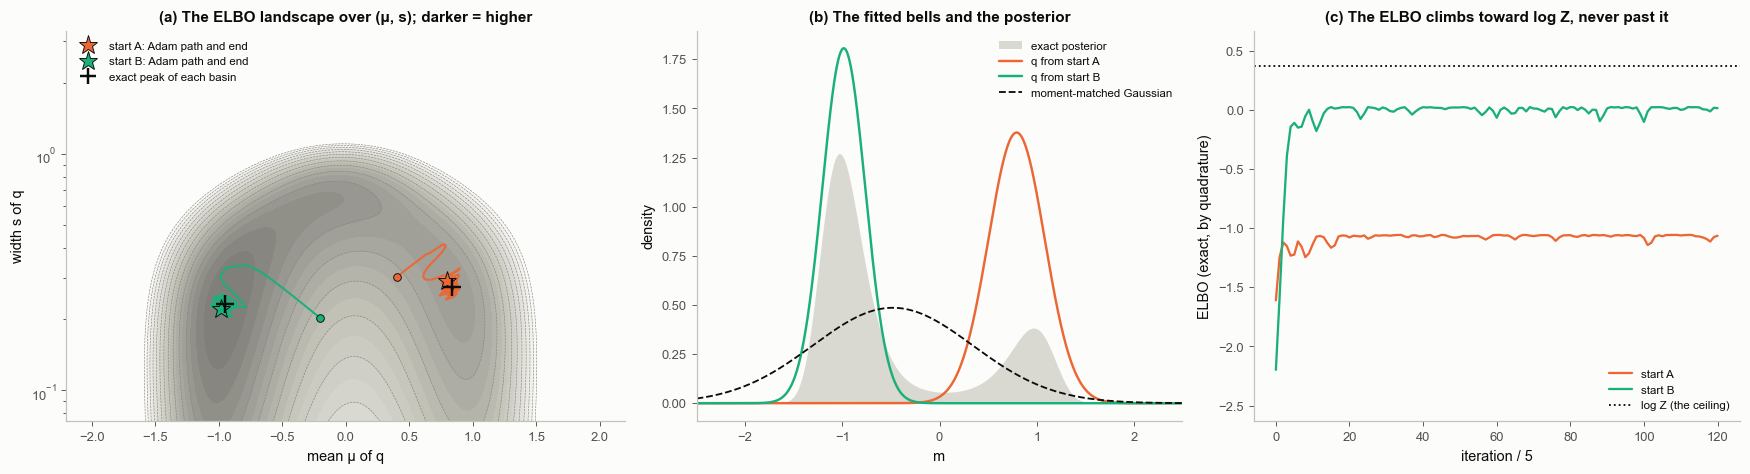

In [3]:
pcol = {"start A": S.ORANGE, "start B": S.AQUA}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ax = axs[0]
cs_ = ax.contourf(MU, np.exp(LS), EL, levels=np.linspace(EL.max() - 6, EL.max(), 25), cmap=S.GREYS, extend="min")
ax.contour(MU, np.exp(LS), EL, levels=np.linspace(EL.max() - 6, EL.max(), 13), colors=S.MUTED, linewidths=0.4)
for k, pth in paths.items():
    ax.plot(pth[:, 0], np.exp(pth[:, 1]), "-", color=pcol[k], lw=1.3)
    ax.plot(*[pth[0, 0], np.exp(pth[0, 1])], "o", color=pcol[k], ms=5, mec=S.INK, mew=0.6)
    ax.plot(*[pth[-1, 0], np.exp(pth[-1, 1])], "*", color=pcol[k], ms=13, mec=S.INK, mew=0.6, label=f"{k}: Adam path and end")
    ax.plot(peaks[k][0], np.exp(peaks[k][1]), "+", color=S.INK, ms=12, mew=1.6)
ax.plot([], [], "+", color=S.INK, ms=10, mew=1.6, label="exact peak of each basin")
ax.set_yscale("log")
ax.set_xlabel("mean μ of q"); ax.set_ylabel("width s of q")
ax.set_title("(a) The ELBO landscape over (μ, s); darker = higher", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left")
ax = axs[1]
ax.fill_between(mg, p1, color="#d9d8d1", lw=0, label="exact posterior")
for k, pth in paths.items():
    mu, ls = pth[-1]
    ax.plot(mg, np.exp(-0.5 * ((mg - mu) / np.exp(ls)) ** 2) / (np.exp(ls) * np.sqrt(2 * np.pi)), color=pcol[k], lw=1.6,
            label=f"q from {k}")
pm, ps = np.sum(mg * p1) * dm, np.sqrt(np.sum(mg ** 2 * p1) * dm - (np.sum(mg * p1) * dm) ** 2)
ax.plot(mg, np.exp(-0.5 * ((mg - pm) / ps) ** 2) / (ps * np.sqrt(2 * np.pi)), color=S.INK, lw=1.2, ls="--",
        label="moment-matched Gaussian")
ax.set_xlim(-2.5, 2.5); ax.set_xlabel("m"); ax.set_ylabel("density")
ax.set_title("(b) The fitted bells and the posterior", fontsize=10)
ax.legend(fontsize=7.5)
ax = axs[2]
for k, pth in paths.items():
    ax.plot([elbo_exact(*ph) for ph in pth[::5]], color=pcol[k], lw=1.5, label=k)
ax.axhline(logZ, color=S.INK, lw=1.2, ls=":", label="log Z (the ceiling)")
ax.set_xlabel("iteration / 5"); ax.set_ylabel("ELBO (exact, by quadrature)")
ax.set_ylim(logZ - 3, logZ + 0.3)
ax.set_title("(c) The ELBO climbs toward log Z, never past it", fontsize=10)
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-21_elbo")
plt.show()

**How to read it.** (a) Every point is one bell, at mean μ and width s; the shading is its ELBO. There are two peaks,
one bell on each bump, and the paths (600 Adam steps each, 8 random draws per step) climb to whichever peak is uphill
from where they start. The stars are where Adam stopped, the crosses the exact peaks: with noisy gradients and a fixed
learning rate, the optimiser hovers near the peak rather than on it (printed). (b) The bells each sit on one bump; none
spreads across both. The dashed bell is what you get by
matching the posterior's mean and variance instead, the mass-covering choice of 2.28: it covers both bumps and puts
its peak in the gap between them. (c) The ELBO rises toward $\ln Z$ and stops below it; the gap is the KL divergence
that remains.

**Worked example.** For the best bell, check $\ln Z = \mathrm{ELBO} + D_{\mathrm{KL}}(q\|p)$ with all three terms
computed independently by quadrature, and compare with the other KL direction.

In [4]:
best = max(paths, key=lambda k: elbo_exact(*paths[k][-1]))
mu, ls = paths[best][-1]
s = np.exp(ls)
q1 = np.exp(-0.5 * ((mg - mu) / s) ** 2) / (s * np.sqrt(2 * np.pi))
ok = q1 > 1e-300
kl_qp = np.sum(q1[ok] * (np.log(q1[ok]) - np.log(p1[ok]))) * dm
kl_pq = np.sum(p1 * (np.log(p1) - np.log(np.maximum(q1, 1e-300)))) * dm
print(f"best start: {best};  q = N({mu:.3f}, {s:.3f}^2)")
print(f"step 1  log Z                 = {logZ:.4f}")
print(f"step 2  ELBO                  = {elbo_exact(mu, ls):.4f}")
print(f"step 3  KL(q || p)            = {kl_qp:.4f}")
print(f"check   ELBO + KL(q || p)     = {elbo_exact(mu, ls) + kl_qp:.4f}  (equals log Z)")
print(f"other direction KL(p || q)    = {kl_pq:.4f}  (large: q misses the other bump)")
print(f"posterior mass on the left bump (m < 0): {np.sum(p1[mg < 0]) * dm:.3f};  q's mass there: {np.sum(q1[mg < 0]) * dm:.3f}")

best start: start B;  q = N(-0.985, 0.221^2)
step 1  log Z                 = 0.3696
step 2  ELBO                  = 0.0136
step 3  KL(q || p)            = 0.3560
check   ELBO + KL(q || p)     = 0.3696  (equals log Z)
other direction KL(p || q)    = 8.2926  (large: q misses the other bump)
posterior mass on the left bump (m < 0): 0.744;  q's mass there: 1.000


**Common misreadings.**
* "A converged ELBO means the answer is right." It means the best member *of the family*, from *this start*, has been
  found. Panel (a) has two converged answers.
* "VI gives the posterior mean." The best bell's mean is the centre of one bump; the posterior mean (printed above via
  the moment-matched bell) lies between the bumps.

## 2. Gradients of an average: the reparameterisation trick

**In plain words.** The ELBO is an average over random draws from $q$, and we want its slope with respect to the
bell's mean and width. Write each draw as $m = \mu + s\,\varepsilon$ with $\varepsilon$ a standard normal number that
does not depend on the bell. Then $m$ moves smoothly when μ or s moves, and ordinary autodiff (notebook 2.17) gives the
slope through $m$. A few draws give a noisy but unbiased slope, the same idea as a mini-batch in 2.10.

**Precisely.** $\nabla_\phi\,\mathbb E_{q_\phi}[f(\mathbf m)] = \mathbb E_{\boldsymbol\varepsilon}
\big[\nabla_\phi f(\boldsymbol\mu + \mathbf s\odot\boldsymbol\varepsilon)\big]$, estimated with $K$ draws; the
estimate's standard deviation falls as $1/\sqrt K$. The code is the `elbo_hat` and `grad_hat` pair above:

In [5]:
print(inspect.getsource(elbo_hat))

def elbo_hat(phi, eps):
    """Monte Carlo ELBO with the reparameterisation m = mu + s * eps (eps ~ N(0, 1) does not depend on phi)."""
    mu, s = phi[0], jnp.exp(phi[1])
    m = mu + s * eps
    return jnp.mean(logp1(m)) + 0.5 * jnp.log(2 * jnp.pi * jnp.e * s ** 2)



saved figures/2-21_reparameterisation.png


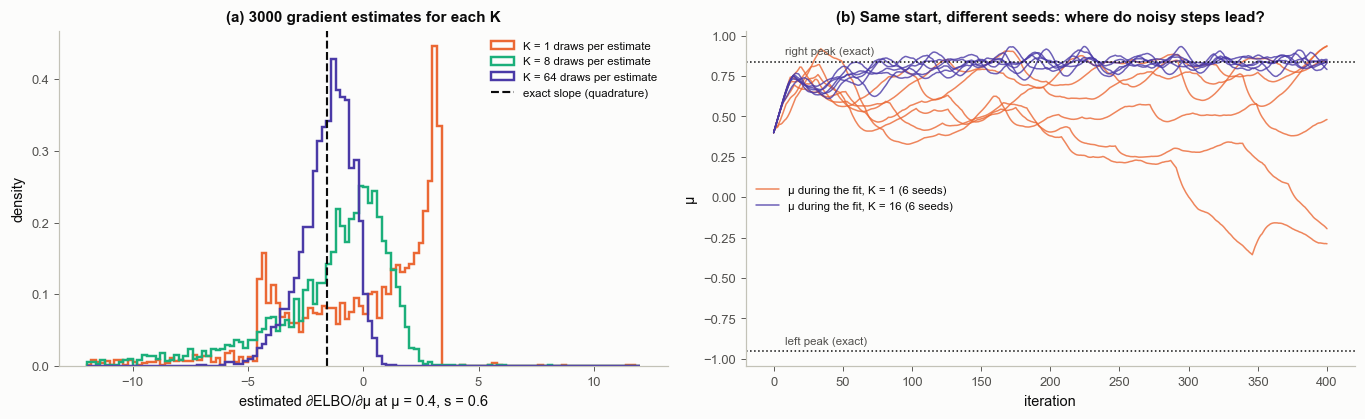

In [6]:
phi0 = jnp.array([0.4, np.log(0.6)])
s0 = 0.6
g_exact = float(np.sum(gh_w * (-10 * ((0.4 + s0 * gh_x) ** 2 - 1) * (0.4 + s0 * gh_x) - 0.6)))   # E[ d ln p / dm ]
Ks = [1, 8, 64]
est = {}
key = jax.random.PRNGKey(7)
vg = jax.jit(jax.vmap(grad_hat, in_axes=(None, 0)))
for K in Ks:
    key, sub = jax.random.split(key)
    est[K] = np.asarray(vg(phi0, jax.random.normal(sub, (3000, K))))[:, 0]
SEEDS2 = range(20, 26)
traces = {K: [fit_1d((0.4, -1.2), K=K, n=400, lr=0.03, seed=s_) for s_ in SEEDS2] for K in (1, 16)}
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9))
ax = axs[0]
bins = np.linspace(-12, 12, 121)
for K, col in zip(Ks, [S.ORANGE, S.AQUA, S.VIOLET]):
    ax.hist(est[K], bins=bins, density=True, histtype="step", lw=1.6, color=col, label=f"K = {K} draws per estimate")
ax.axvline(g_exact, color=S.INK, lw=1.4, ls="--", label="exact slope (quadrature)")
ax.set_xlabel("estimated ∂ELBO/∂μ at μ = 0.4, s = 0.6"); ax.set_ylabel("density")
ax.set_title("(a) 3000 gradient estimates for each K", fontsize=10)
ax.legend(fontsize=7.5)
ax = axs[1]
for K, col in zip((1, 16), [S.ORANGE, S.VIOLET]):
    for i_, tr in enumerate(traces[K]):
        ax.plot(tr[:, 0], color=col, lw=1.0, alpha=0.8, label=f"μ during the fit, K = {K} ({len(SEEDS2)} seeds)" if i_ == 0 else None)
for k in starts:
    ax.axhline(peaks[k][0], color=S.INK, ls=":", lw=1)
ax.text(8, peaks["start A"][0] + 0.03, "right peak (exact)", va="bottom", fontsize=7.5, color=S.INK2)
ax.text(8, peaks["start B"][0] + 0.03, "left peak (exact)", va="bottom", fontsize=7.5, color=S.INK2)
ax.set_xlabel("iteration"); ax.set_ylabel("μ")
ax.set_title("(b) Same start, different seeds: where do noisy steps lead?", fontsize=10)
ax.legend(fontsize=7.5)
fig.tight_layout()
bk.savefig(fig, "2-21_reparameterisation")
plt.show()

**How to read it.** (a) Each histogram is 3000 slope estimates at the same bell; all are centred on the exact slope,
and more draws make them narrower. (b) Six fits from start A for each K. Read the printed end points: with one draw per
step the path is jittery, and noise can carry a run over the ridge into the other basin; with 16 draws the runs follow
nearly the same path. Which peak you reach is part of the answer, so the seed matters.

**Worked example.** Exact slope, and mean and spread of the estimates for each K (printed below); the spread times
$\sqrt K$ should stay roughly constant.

In [7]:
print(f"exact slope dELBO/dmu at (0.4, 0.6): {g_exact:.3f}")
for K in Ks:
    print(f"K = {K:2d}: mean of estimates {est[K].mean():7.3f}, sd {est[K].std():6.3f}, sd * sqrt(K) = {est[K].std() * np.sqrt(K):.3f}")
for K in (1, 16):
    ends = np.array([tr[-1, 0] for tr in traces[K]])
    jit_ = np.mean([tr[-100:, 0].std() for tr in traces[K]])
    print(f"fit with K = {K:2d}: final mu of the {len(ends)} seeds {np.round(ends, 2)}; runs with mu < 0: "
          f"{np.sum(ends < 0)}; mean sd of mu over the last 100 iterations {jit_:.3f}")
print("(mu < 0 after 400 steps: past the ridge between the basins and heading for the left bump)")

exact slope dELBO/dmu at (0.4, 0.6): -1.560
K =  1: mean of estimates  -1.406, sd  7.326, sd * sqrt(K) = 7.326
K =  8: mean of estimates  -1.631, sd  3.215, sd * sqrt(K) = 9.094
K = 64: mean of estimates  -1.539, sd  1.107, sd * sqrt(K) = 8.859
fit with K =  1: final mu of the 6 seeds [ 0.94  0.93  0.83  0.48 -0.29 -0.19]; runs with mu < 0: 2; mean sd of mu over the last 100 iterations 0.091
fit with K = 16: final mu of the 6 seeds [0.84 0.79 0.84 0.85 0.84 0.83]; runs with mu < 0: 0; mean sd of mu over the last 100 iterations 0.027
(mu < 0 after 400 steps: past the ridge between the basins and heading for the left bump)


**Common misreading.** "Noisy gradients are a bug." They are the price of never computing the expectation exactly;
the estimate is unbiased (its mean matches the exact slope, printed above), and K or the learning rate trades noise
against cost.

## 3. Three families on four shapes

**In plain words.** The family decides what VI can say.
* **Mean field**: one independent bell per parameter. It cannot represent a correlation.
* **Full rank**: one tilted bell (a full covariance matrix). It can tilt, but not bend or split.
* **Normalizing flow**: start from a simple bell and push it through a chain of invertible warps learned by the
  optimiser. The warps can bend the bell into a banana, and flexible ones can fold it.

**Precisely.** A flow writes $\mathbf m = f_K\circ\dots\circ f_1(\mathbf z)$, $\mathbf z\sim\mathcal N(\mathbf 0,
\mathbf I)$, with each $f$ invertible, so the change-of-variables formula gives the density:
$\ln q(\mathbf m) = \ln\mathcal N(\mathbf z) - \sum_k\ln|\det\partial f_k/\partial\mathbf z_{k-1}|$. **IAF**: each
warp shifts and scales coordinate $i$ by amounts computed from coordinates $1..i-1$ by a small network (affine in
$m_i$). **BNAF**: each warp is a small monotone neural network per coordinate (non-affine). NumPyro autoguides:
`AutoDiagonalNormal` (mean field; the same family as `AutoNormal`, but with its density in one vector),
`AutoMultivariateNormal` (full rank), `AutoIAFNormal` (4 warps, hidden layers 32-32), `AutoBNAFNormal` (2 warps,
hidden factors 16-16).

**How each is scored.** Two numbers per panel, both from 8,000 draws and a smoothed histogram on the same grid as the
exact posterior: **coverage** = share of the exact posterior inside the method's own 90 % region (low = the method is
too narrow or misses a part), and **precision** = share of the method's draws inside the exact 90 % region (low = the
method puts mass where the posterior has little). A correct method gives about 0.9 for both; the first row of the
printed table shows what exact draws score, which is the scoring noise.

In [8]:
targets = {"correlated": P.correlated(), "banana": P.location(kind="banana"), "two modes": P.location(kind="bimodal"),
           "funnel": P.funnel(dim=2, scale_v=1.5)}
extents = {"funnel": (-6.0, 6.0, -12.0, 12.0)}
grids = {k: P.grid(t, extent=extents.get(k), n=300) for k, t in targets.items()}
for k, g in grids.items():
    edge = (g.P[0].sum() + g.P[-1].sum()) * g.dx + (g.P[:, 0].sum() + g.P[:, -1].sum()) * g.dy
    print(f"{k:11s}: exact posterior density summed along the grid edges = {edge:.1e} (small = grid wide enough)")

FAMILIES = [("mean field", AutoDiagonalNormal, {}, 2e-2, 3000),
            ("full rank", AutoMultivariateNormal, {}, 2e-2, 3000),
            ("IAF flow", AutoIAFNormal, dict(num_flows=4, hidden_dims=[32, 32]), 5e-3, 4000),
            ("BNAF flow", AutoBNAFNormal, dict(num_flows=2, hidden_factors=[16, 16]), 5e-3, 4000)]


def zoo_model(t):
    lp = t._logp_fn

    def model():
        m = numpyro.sample("m", dist.ImproperUniform(constraints.real_vector, (), (t.dim,)))
        numpyro.factor("lp", lp(m))
    return model


def run_vi(model, fam, seed=0, model_kw=None, n_draw=8000, site="m"):
    name, Guide, kw, lr, steps = fam
    guide = Guide(model, **kw)
    svi = SVI(model, guide, Adam(lr), Trace_ELBO(num_particles=8))
    t0 = time.time()
    res = svi.run(jax.random.PRNGKey(seed), steps, progress_bar=False, **(model_kw or {}))
    draws = np.asarray(guide.sample_posterior(jax.random.PRNGKey(seed + 1), res.params, sample_shape=(n_draw,))[site])
    return dict(X=draws, time=time.time() - t0, n_grad=steps * 8, loss=np.asarray(res.losses))


def run_nuts(model, seed=0, model_kw=None, site="m", dense=False, warm=1000, n=2000):
    mc = MCMC(NUTS(model, dense_mass=dense), num_warmup=warm, num_samples=n, num_chains=4, progress_bar=False)
    t0 = time.time()
    mc.run(jax.random.PRNGKey(seed), extra_fields=("num_steps", "diverging"), **(model_kw or {}))
    Xc = np.asarray(mc.get_samples(group_by_chain=True)[site])
    ex = mc.get_extra_fields()
    return dict(X=Xc.reshape(-1, Xc.shape[-1]), Xc=Xc, time=time.time() - t0, n_grad=int(np.sum(ex["num_steps"])),
                div=int(np.sum(ex["diverging"])))


def region90(g, X, smooth=3.0):
    """The method's own 90 % region on the grid, from a smoothed histogram of its draws X (n, 2)."""
    xe = np.r_[g.X[0] - g.dx / 2, g.X[0, -1] + g.dx / 2]
    ye = np.r_[g.Y[:, 0] - g.dy / 2, g.Y[-1, 0] + g.dy / 2]
    H, _, _ = np.histogram2d(X[:, 1], X[:, 0], bins=[ye, xe])
    H = gaussian_filter(H, smooth)
    H /= H.sum()
    return H >= P.hdr_levels(H, (0.9,))[0.9]


def score(g, X):
    cover = float(g.P[region90(g, X)].sum() * g.dx * g.dy)
    return cover, g.inside(X, 0.9)


zoo = {}
for tname, t in targets.items():
    model = zoo_model(t)
    zoo[(tname, "NUTS")] = run_nuts(model, seed=1)
    for fam in FAMILIES:
        zoo[(tname, fam[0])] = run_vi(model, fam, seed=0)
COLS = ["NUTS"] + [f[0] for f in FAMILIES]
print(f"\n{'target':11s} {'method':11s} {'coverage':>8s} {'precision':>9s} {'gradients':>9s} {'time (s)':>8s}")
for tname, g in grids.items():
    c_, p_ = score(g, g.sample(8000, np.random.default_rng(0)))
    print(f"{tname:11s} {'exact draws':11s} {c_:8.2f} {p_:9.2f} {'-':>9s} {'-':>8s}")
    for mth in COLS:
        r = zoo[(tname, mth)]
        c_, p_ = score(g, r["X"])
        r["score"] = (c_, p_)
        print(f"{tname:11s} {mth:11s} {c_:8.2f} {p_:9.2f} {r['n_grad']:9d} {r['time']:8.1f}"
              + (f"   ({r['div']} divergent NUTS transitions)" if mth == "NUTS" else ""))

correlated : exact posterior density summed along the grid edges = 1.6e-07 (small = grid wide enough)
banana     : exact posterior density summed along the grid edges = 4.8e-03 (small = grid wide enough)
two modes  : exact posterior density summed along the grid edges = 1.8e-114 (small = grid wide enough)
funnel     : exact posterior density summed along the grid edges = 5.7e-04 (small = grid wide enough)



target      method      coverage precision gradients time (s)
correlated  exact draws     0.95      0.90         -        -
correlated  NUTS            0.94      0.91    105928      0.7   (0 divergent NUTS transitions)
correlated  mean field      0.24      0.90     24000      0.9
correlated  full rank       0.94      0.92     24000      0.9
correlated  IAF flow        0.91      0.95     32000      1.6
correlated  BNAF flow       0.93      0.94     32000      3.6
banana      exact draws     0.91      0.90         -        -
banana      NUTS            0.90      0.92     58921      0.6   (27 divergent NUTS transitions)
banana      mean field      0.57      0.94     24000      0.5
banana      full rank       0.57      0.94     24000      0.2
banana      IAF flow        0.46      0.96     32000      0.6
banana      BNAF flow       0.87      0.93     32000      0.9
two modes   exact draws     0.97      0.91         -        -
two modes   NUTS            0.96      0.91     25306      0.6   

saved figures/2-21_families.png


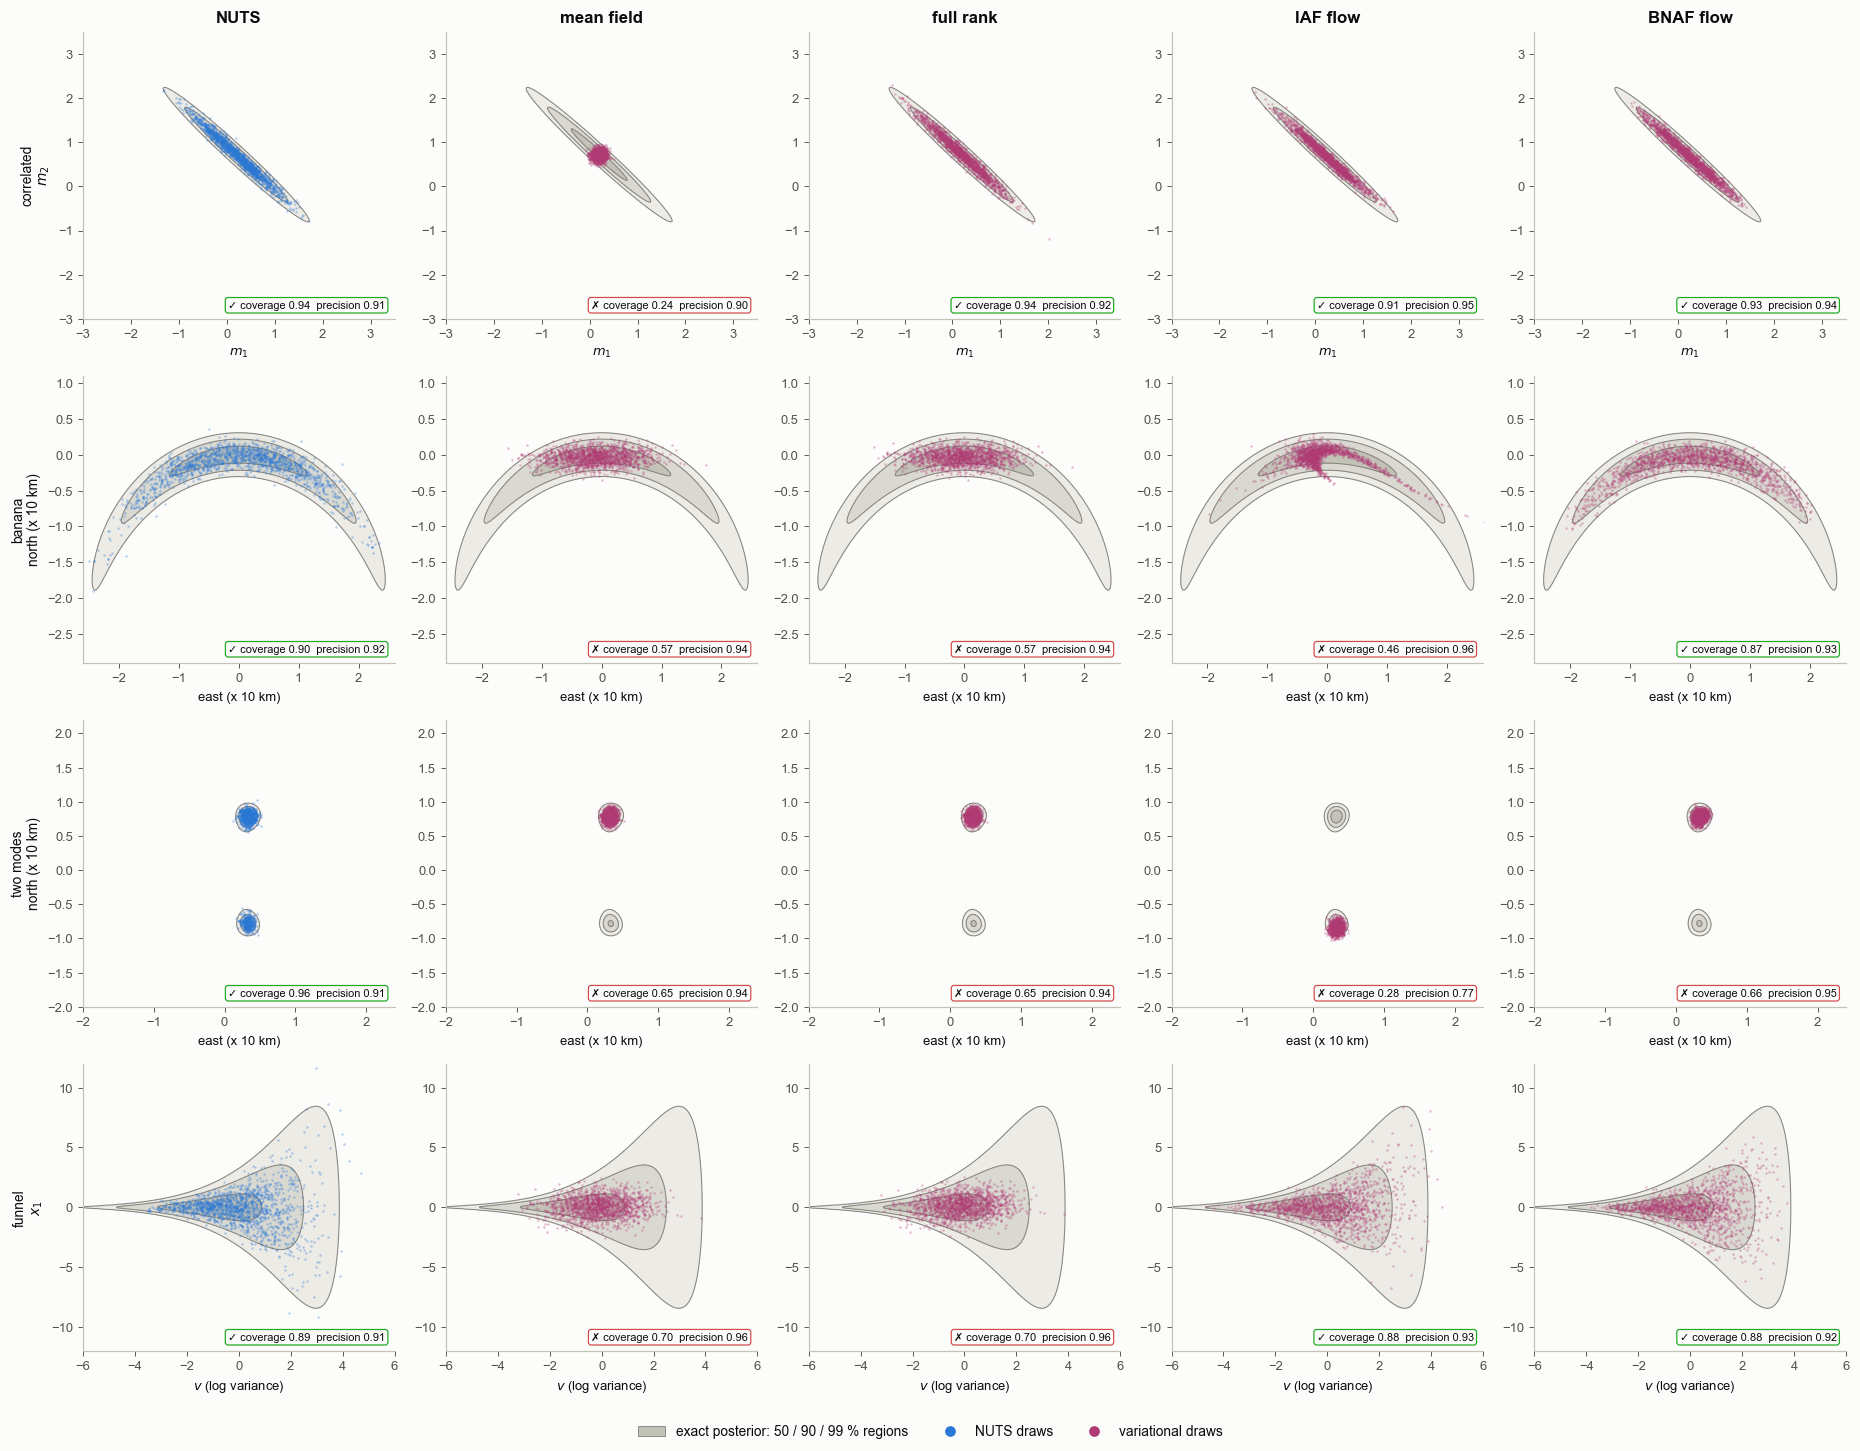

In [9]:
fig, axs = plt.subplots(4, 5, figsize=(17, 13.2))
for i, (tname, t) in enumerate(targets.items()):
    g = grids[tname]
    for j, mth in enumerate(COLS):
        ax = axs[i, j]
        BP.density(ax, g)
        X = zoo[(tname, mth)]["X"]
        BP.samples(ax, X, NU if mth == "NUTS" else VI, n_max=1500, s=2.5, alpha=0.35)
        ax.set_xlim(g.X[0, 0], g.X[0, -1]); ax.set_ylim(g.Y[0, 0], g.Y[-1, 0])
        c_, p_ = zoo[(tname, mth)]["score"]
        S.badge(ax, f"coverage {c_:.2f}  precision {p_:.2f}", ok=(c_ > 0.8 and p_ > 0.8), loc="lower right", fs=7.2)
        if i == 0:
            ax.set_title(mth, fontsize=11, fontweight="bold")
        if j == 0:
            ax.set_ylabel(f"{tname}\n{t.labels[1]}", fontsize=9)
        ax.set_xlabel(t.labels[0], fontsize=8.5)
fig.legend(handles=BP.legend_handles([("exact posterior: 50 / 90 / 99 % regions", "#c3c2b7", "region"),
                                      ("NUTS draws", NU, "dot"), ("variational draws", VI, "dot")]),
           loc="lower center", ncol=3, fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.025, 1, 1))
bk.savefig(fig, "2-21_families")
plt.show()

**How to read it.** Grey: exact posterior regions. Blue: NUTS draws; magenta: draws from the fitted $q$. Badge ✓ when
both scores exceed 0.8. Read each row against the printed table.
* **Correlated.** Mean field draws an upright ellipse inside the tilted one: its draws all land in the right place
  (high precision), but it covers only part of the posterior (low coverage). Full rank tilts and fits.
* **Banana.** The Gaussian families sit on the thickest part of the arc. BNAF bends along it; IAF, in this
  configuration and from this start, collapses onto part of the arc (scores printed). A flow *can* bend; whether a
  given fit does is not guaranteed.
* **Two modes.** Here every variational family settles on one mode: mode seeking, as in section 1. NUTS's pooled draws
  cover both, but only because its four chains landed on different sides; section 4(b) shows that each chain stays
  on its side.
* **Funnel.** The Gaussian families cannot narrow at the neck and widen at the mouth at the same time; look at how the
  flows handle it.
* **Cost.** VI's gradient count is steps × 8 draws per step (printed), fixed in advance; NUTS's is whatever its trees
  needed. In two dimensions both are seconds.

## 4. Mode seeking and under-dispersion, measured

**(a) Under-dispersion has a formula.** For a Gaussian posterior with precision matrix $\boldsymbol\Lambda =
\mathbf C^{-1}$, the best mean-field fit has variances $1/\Lambda_{ii}$, the *conditional* variances, never the
marginal ones $C_{ii}$. In two dimensions with correlation ρ that is a width ratio of $\sqrt{1-\rho^2}$.

**Worked example** on the correlated target (its posterior is exactly Gaussian):

In [10]:
m_c, C_c = targets["correlated"].exact
rho = C_c[0, 1] / np.sqrt(C_c[0, 0] * C_c[1, 1])
Lam = np.linalg.inv(C_c)
Xmf = zoo[("correlated", "mean field")]["X"]
print(f"step 1  exact posterior sd       = {np.sqrt(np.diag(C_c)).round(3)}, correlation rho = {rho:.3f}")
print(f"step 2  mean-field theory sd     = 1/sqrt(Lambda_ii) = {(1 / np.sqrt(np.diag(Lam))).round(3)}")
print(f"step 3  ratio sqrt(1 - rho^2)    = {np.sqrt(1 - rho ** 2):.3f}")
print(f"check   fitted mean-field sd     = {Xmf.std(0).round(3)}  (AutoDiagonalNormal, section 3)")

step 1  exact posterior sd       = [0.501 0.501], correlation rho = -0.983
step 2  mean-field theory sd     = 1/sqrt(Lambda_ii) = [0.091 0.091]
step 3  ratio sqrt(1 - rho^2)    = 0.182
check   fitted mean-field sd     = [0.084 0.083]  (AutoDiagonalNormal, section 3)


**(b) Which mode do you get?** Each family fitted to the two-mode target from 6 different random starts
(seeds), and NUTS's 4 chains: the share of each answer's mass in the northern mode, against the exact share.

saved figures/2-21_mode_seeking.png


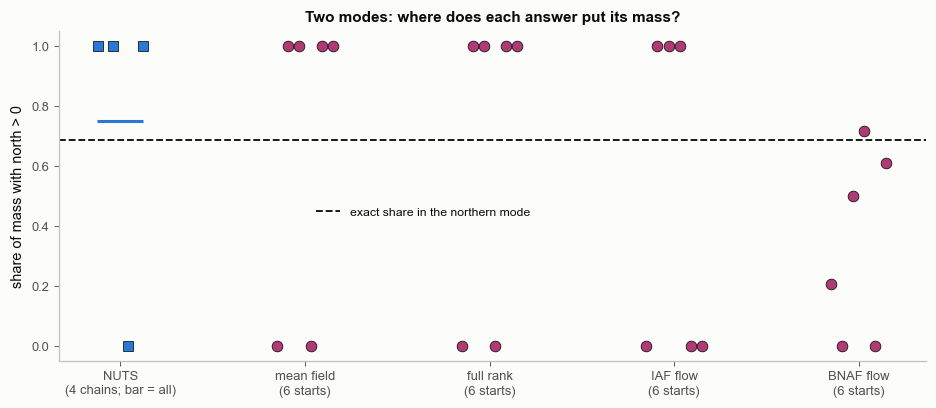

exact share in the northern mode: 0.686
mean field : shares from 6 starts [0. 1. 1. 0. 1. 1.]
full rank  : shares from 6 starts [0. 1. 1. 0. 1. 1.]
IAF flow   : shares from 6 starts [0. 1. 1. 1. 0. 0.]
BNAF flow  : shares from 6 starts [0.2  0.   0.5  0.72 0.   0.61]
NUTS chains: [1. 1. 0. 1.], pooled 0.750; R-hat of the north coordinate 1.53


In [11]:
g2 = grids["two modes"]
north_exact = g2.mass(lambda X, Y: Y > 0)
model2 = zoo_model(targets["two modes"])
shares = {fam[0]: [float(np.mean(run_vi(model2, fam, seed=10 + s_, n_draw=4000)["X"][:, 1] > 0)) for s_ in range(6)]
          for fam in FAMILIES}
Xc2 = zoo[("two modes", "NUTS")]["Xc"]
shares_nuts = [float(np.mean(Xc2[c][:, 1] > 0)) for c in range(4)]
fig, ax = plt.subplots(figsize=(8.6, 3.8))
for j, fam in enumerate(FAMILIES):
    ax.plot(np.full(6, j + 1) + np.linspace(-0.15, 0.15, 6), shares[fam[0]], "o", color=VI, ms=7, mec=S.INK, mew=0.5)
ax.plot(np.zeros(4) + np.linspace(-0.12, 0.12, 4), shares_nuts, "s", color=NU, ms=7, mec=S.INK, mew=0.5)
ax.plot(0, np.mean(shares_nuts), "_", color=NU, ms=30, mew=2)
ax.axhline(north_exact, color=S.INK, ls="--", lw=1.2, label="exact share in the northern mode")
ax.set_xticks(range(5)); ax.set_xticklabels(["NUTS\n(4 chains; bar = all)"] + [f[0] + "\n(6 starts)" for f in FAMILIES])
ax.set_ylabel("share of mass with north > 0"); ax.set_ylim(-0.05, 1.05)
ax.set_title("Two modes: where does each answer put its mass?", fontsize=10)
ax.legend(fontsize=8, loc="center", bbox_to_anchor=(0.42, 0.45))
fig.tight_layout()
bk.savefig(fig, "2-21_mode_seeking")
plt.show()
print(f"exact share in the northern mode: {north_exact:.3f}")
for k, v in shares.items():
    print(f"{k:11s}: shares from 6 starts {np.round(v, 2)}")
print(f"NUTS chains: {np.round(shares_nuts, 2)}, pooled {np.mean(shares_nuts):.3f}; "
      f"R-hat of the north coordinate {D.rhat(Xc2[..., 1]):.2f}")

**How to read it.** A share near 0 or 1 means the fitted distribution sits in one mode only. Read the printed shares:
for mean field, full rank and IAF every start commits to one side, and which side depends on the seed, so a single
run gives no warning that the other mode exists. BNAF, the most flexible family, sometimes spreads its mass over both
modes and sometimes does not, again depending on the start. NUTS's chains each stay on one side too; the pooled share
is only as good as the luck of where the chains started, and R-hat (notebook 2.19, printed) flags it.

## 5. Afterslip on one patch: friction from the first month of GPS

**The problem.** One fault patch (a spring-slider) after an earthquake raised its shear stress by Δτ = 3 MPa
(known, as when Δτ comes from a coseismic slip model). Afterslip follows $v = 2v_0\sinh(\tau/a\sigma)$ and
$\dot\tau = -k v$; a GPS site records $u = g\,s$. The unknowns are $\ln a\sigma$ and $\ln v_0$ with the uniform prior
box of `bayeskit.afterslip` (aσ 0.2-2 MPa, $v_0$ 0.001-1 m/yr). Data: the 23 epochs of the module's time grid within
the first 30 days, σ = 2 mm. True values aσ = 0.6 MPa, $v_0$ = 0.02 m/yr.

**The forward model is exact.** This ODE separates: $\tanh\!\big(\tau(t)/2a\sigma\big) = \tanh(\Delta\tau/2a\sigma)\,
e^{-2kv_0t/a\sigma}$ and $s = (\Delta\tau-\tau)/k$. The cell checks it against the diffrax black box on prior draws.
It is closed form, so NUTS and VI need only microseconds per gradient.

In [12]:
k_sp, g_sp = AS.SP_DEFAULTS["k"], AS.SP_DEFAULTS["g"]
t30 = AS.T_OBS[AS.T_OBS <= 30 / 365.25 + 1e-9]
sig_sp = 2.0


def u_mm(la, lv, dtau, t):
    """Exact single-patch surface displacement (mm) at times t (years)."""
    a, v0 = jnp.exp(la), jnp.exp(lv)
    z = jnp.tanh(dtau / (2 * a)) * jnp.exp(-2 * k_sp * v0 * jnp.asarray(t) / a)
    return 1000.0 * g_sp * (dtau - 2 * a * jnp.arctanh(z)) / k_sp


th_bb = AS.sample_theta(np.random.default_rng(0), 300)
u_bb = np.asarray(jax.jit(jax.vmap(lambda q: AS.single_patch_series(q, AS.T_OBS)))(jnp.asarray(th_bb))) * 1000
u_ex = np.asarray(jax.vmap(lambda q: u_mm(q[0], q[1], q[2], AS.T_OBS))(jnp.asarray(th_bb)))
print(f"exact solution vs diffrax over 300 prior draws, 40 epochs: max difference {np.abs(u_ex - u_bb).max():.1e} mm "
      f"(largest displacement {np.abs(u_bb).max():.0f} mm)")
th_true = np.array([np.log(0.6), np.log(0.02), 3.0])
y_sp = np.asarray(u_mm(*th_true, t30)) + sig_sp * np.random.default_rng(1).standard_normal(t30.size)
lo2, hi2 = AS.SP_BOUNDS[:2, 0], AS.SP_BOUNDS[:2, 1]


def model_sp(y=None):
    th = numpyro.sample("th", dist.Uniform(jnp.asarray(lo2), jnp.asarray(hi2)).to_event(1))
    numpyro.sample("y", dist.Normal(u_mm(th[0], th[1], 3.0, t30), sig_sp).to_event(1), obs=y)


def logpost_sp(th):
    inside = jnp.all((th >= lo2) & (th <= hi2))
    ll = -0.5 * jnp.sum(((u_mm(th[0], th[1], 3.0, t30) - y_sp) / sig_sp) ** 2)
    return jnp.where(inside, ll, -jnp.inf)


tgt_sp = P.Target(logpost_sp, 2, "afterslip, Δτ known", labels=("ln aσ  (aσ in MPa)", "ln v₀  (v₀ in m/yr)"))
g_wide = P.grid(tgt_sp, extent=(lo2[0], hi2[0], lo2[1], hi2[1]), n=400)
mx_, my_ = g_wide.mean
sx_, sy_ = np.sqrt(np.diag(g_wide.cov))
EXT_SP = (mx_ - 6 * sx_, mx_ + 6 * sx_, my_ - 6 * sy_, my_ + 6 * sy_)
g_sp_ = P.grid(tgt_sp, extent=EXT_SP, n=300)
print(f"{t30.size} epochs; exact posterior: sd(ln aσ) = {np.sqrt(g_sp_.cov[0, 0]):.3f}, sd(ln v0) = {np.sqrt(g_sp_.cov[1, 1]):.3f}, "
      f"correlation {g_sp_.cov[0, 1] / np.sqrt(g_sp_.cov[0, 0] * g_sp_.cov[1, 1]):.3f}")
print(f"share of the posterior inside the zoomed window (from the full-box grid): "
      f"{g_wide.mass(lambda X, Y: (X > EXT_SP[0]) & (X < EXT_SP[1]) & (Y > EXT_SP[2]) & (Y < EXT_SP[3])):.4f}")

sp = {"NUTS": run_nuts(model_sp, seed=2, model_kw=dict(y=jnp.asarray(y_sp)), site="th", dense=True)}
for fam in FAMILIES:
    sp[fam[0]] = run_vi(model_sp, fam, seed=0, model_kw=dict(y=jnp.asarray(y_sp)), site="th")
print(f"\n{'method':11s} {'coverage':>8s} {'precision':>9s} {'sd ln aσ':>8s} {'sd ln v0':>8s} {'gradients':>9s} {'time (s)':>8s}")
c_, p_ = score(g_sp_, g_sp_.sample(8000, np.random.default_rng(0)))
print(f"{'exact':11s} {c_:8.2f} {p_:9.2f} {np.sqrt(g_sp_.cov[0, 0]):8.3f} {np.sqrt(g_sp_.cov[1, 1]):8.3f}")
for mth, r in sp.items():
    r["score"] = score(g_sp_, r["X"])
    print(f"{mth:11s} {r['score'][0]:8.2f} {r['score'][1]:9.2f} {r['X'][:, 0].std():8.3f} {r['X'][:, 1].std():8.3f} "
          f"{r['n_grad']:9d} {r['time']:8.1f}")
print(f"NUTS: {sp['NUTS']['div']} divergent transitions; R-hat {[round(D.rhat(sp['NUTS']['Xc'][..., i]), 3) for i in range(2)]}")

exact solution vs diffrax over 300 prior draws, 40 epochs: max difference 2.6e-05 mm (largest displacement 973 mm)


23 epochs; exact posterior: sd(ln aσ) = 0.131, sd(ln v0) = 0.568, correlation 0.995
share of the posterior inside the zoomed window (from the full-box grid): 1.0000



method      coverage precision sd ln aσ sd ln v0 gradients time (s)
exact           0.97      0.90    0.131    0.568
NUTS            0.97      0.92    0.131    0.556    134664      1.0
mean field      0.12      0.62    0.006    0.028     24000      1.0
full rank       0.18      0.66    0.013    0.064     24000      0.3
IAF flow        0.92      0.77    0.128    0.538     32000      0.7
BNAF flow       0.52      0.94    0.060    0.242     32000      1.1
NUTS: 14 divergent transitions; R-hat [1.005, 1.005]


saved figures/2-21_afterslip.png


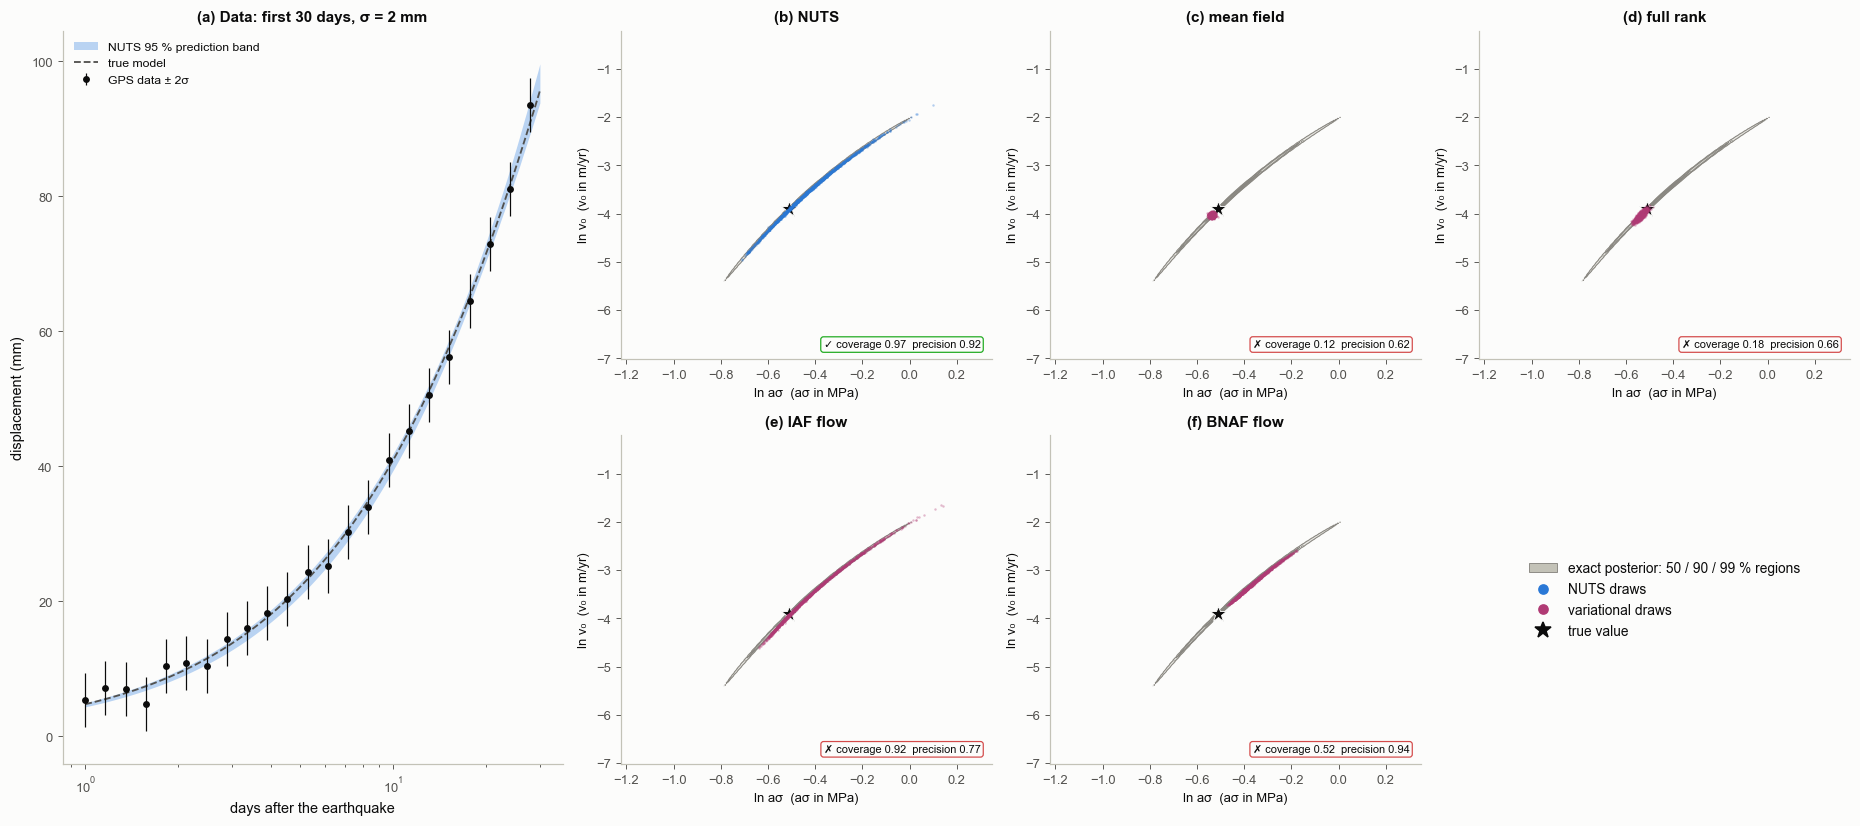

In [13]:
fig = plt.figure(figsize=(17, 7.6))
gs = fig.add_gridspec(2, 4, width_ratios=[1.35, 1, 1, 1])
ax = fig.add_subplot(gs[:, 0])
tt = np.geomspace(t30[0], 30 / 365.25, 200)
pred = np.asarray(jax.vmap(lambda q: u_mm(q[0], q[1], 3.0, tt))(jnp.asarray(sp["NUTS"]["X"][::8])))
lo_, hi_ = np.percentile(pred, [2.5, 97.5], axis=0)
ax.fill_between(tt * 365.25, lo_, hi_, color="#b9d3f2", lw=0, label="NUTS 95 % prediction band")
ax.plot(tt * 365.25, np.asarray(u_mm(*th_true, tt)), color=S.INK2, lw=1.2, ls="--", label="true model")
ax.errorbar(t30 * 365.25, y_sp, yerr=2 * sig_sp, fmt="o", ms=3.5, color=S.INK, lw=0.8, capsize=0, label="GPS data ± 2σ")
ax.set_xscale("log"); ax.set_xlabel("days after the earthquake"); ax.set_ylabel("displacement (mm)")
ax.set_title("(a) Data: first 30 days, σ = 2 mm", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
for j, mth in enumerate(COLS):
    ax = fig.add_subplot(gs[j // 3, 1 + j % 3])
    BP.density(ax, g_sp_)
    BP.samples(ax, sp[mth]["X"], NU if mth == "NUTS" else VI, n_max=1500, s=2.5, alpha=0.35)
    ax.plot(*th_true[:2], "*", color=S.INK, ms=11, mec=S.SURFACE, mew=0.6)
    ax.set_xlim(EXT_SP[0], EXT_SP[1]); ax.set_ylim(EXT_SP[2], EXT_SP[3])
    c_, p_ = sp[mth]["score"]
    S.badge(ax, f"coverage {c_:.2f}  precision {p_:.2f}", ok=(c_ > 0.8 and p_ > 0.8), loc="lower right", fs=7.2)
    ax.set_title(f"({'bcdef'[j]}) {mth}", fontsize=10)
    ax.set_xlabel(tgt_sp.labels[0], fontsize=8.5); ax.set_ylabel(tgt_sp.labels[1], fontsize=8.5)
ax = fig.add_subplot(gs[1, 3])
ax.axis("off")
ax.legend(handles=BP.legend_handles([("exact posterior: 50 / 90 / 99 % regions", "#c3c2b7", "region"),
                                     ("NUTS draws", NU, "dot"), ("variational draws", VI, "dot")]) +
          [plt.Line2D([], [], marker="*", ls="", color=S.INK, ms=11, label="true value")], loc="center", fontsize=9)
fig.tight_layout()
bk.savefig(fig, "2-21_afterslip")
plt.show()

**How to read it.** (a) One month of afterslip data and the spread of predictions from the NUTS posterior. (b)-(f) The
exact posterior is a thin, curved banana: a month of data pins down the early slip rate, which depends on
$v_0\,e^{\Delta\tau/a\sigma}$, better than it separates $a\sigma$ from $v_0$, and the trade-off curves because $\ln v_0$
enters against $\Delta\tau/a\sigma$, not against $\ln a\sigma$. The autoguides fit in an unconstrained space (each
bounded parameter is mapped to the real line), so even the "Gaussian" families are not exactly Gaussian here. Read the
printed scores and widths:
* mean field is the narrowest by far, the correlated-target lesson of section 4 in a physical problem;
* full rank tilts with the banana but, unable to bend, covers only a short straight piece of it: the mode-seeking KL
  prefers a short piece it fits well to a long one it fits badly;
* of the flows, IAF follows most of the banana here, while BNAF covers only part of it: the reverse of their
  order on the zoo banana in section 3. Flexibility helps only if the optimisation finds it;
* NUTS with a dense mass matrix follows the banana (its R-hat and divergences are printed).

## 6. One knob: let Δτ be unknown too

Now Δτ joins the unknowns (prior 1-5 MPa), with the same 23 epochs. In the first month the solution depends on $v_0$
and Δτ mainly through $v_0\,e^{\Delta\tau/a\sigma}$, so one combination is pinned down and the other is not: a
**non-identifiable direction**, along which the posterior is as wide as the prior box allows. The exact answer is a
grid: for each of 150 × 150 values of $(\ln v_0, \Delta\tau)$, the likelihood is summed over 1,500 values of
$\ln a\sigma$ (the posterior is a thin sheet in that direction, so a coarse grid would alias it).

In [14]:
from jax.scipy.special import logsumexp
lo3, hi3 = AS.SP_BOUNDS[:, 0], AS.SP_BOUNDS[:, 1]
la_fine = jnp.linspace(lo3[0], hi3[0], 1500)


def sum_over_asig(q):
    """For one (ln v0, dtau): log of the likelihood summed over ln a_sigma, and the first two moments of ln a_sigma."""
    ll = jax.vmap(lambda a: -0.5 * jnp.sum(((u_mm(a, q[0], q[1], t30) - y_sp) / sig_sp) ** 2))(la_fine)
    lz = logsumexp(ll)
    w = jnp.exp(ll - lz)
    return lz, jnp.sum(w * la_fine), jnp.sum(w * la_fine ** 2)


n3 = 150
lv3, dt3 = np.linspace(lo3[1], hi3[1], n3), np.linspace(lo3[2], hi3[2], n3)
YY, XX = np.meshgrid(dt3, lv3, indexing="ij")                # rows = dtau, columns = ln v0
lz3, m1_, m2_ = [np.asarray(o).reshape(n3, n3) for o in
                 jax.jit(jax.vmap(sum_over_asig))(jnp.asarray(np.column_stack([XX.ravel(), YY.ravel()])))]
W3 = np.exp(lz3 - lz3.max())
W3 /= W3.sum()
d3 = (lv3[1] - lv3[0], dt3[1] - dt3[0])
marg = W3 / (d3[0] * d3[1])
g3 = P.Grid(XX, YY, marg, d3[0], d3[1], P.hdr_levels(marg))
ma = np.sum(W3 * m1_)
mean3 = np.array([ma, np.sum(W3 * XX), np.sum(W3 * YY)])
sd3 = np.sqrt(np.array([np.sum(W3 * m2_) - ma ** 2, np.sum(W3 * XX ** 2) - mean3[1] ** 2, np.sum(W3 * YY ** 2) - mean3[2] ** 2]))


def model_sp3(y=None):
    th = numpyro.sample("th", dist.Uniform(jnp.asarray(lo3), jnp.asarray(hi3)).to_event(1))
    numpyro.sample("y", dist.Normal(u_mm(th[0], th[1], th[2], t30), sig_sp).to_event(1), obs=y)


kn = {"NUTS": run_nuts(model_sp3, seed=3, model_kw=dict(y=jnp.asarray(y_sp)), site="th", dense=True)}
for fam in [FAMILIES[0], FAMILIES[1], FAMILIES[3]]:
    kn[fam[0]] = run_vi(model_sp3, fam, seed=0, model_kw=dict(y=jnp.asarray(y_sp)), site="th")
print(f"{'':11s} {'mean ln aσ':>10s} {'mean ln v0':>10s} {'mean Δτ':>8s} {'sd ln aσ':>8s} {'sd ln v0':>8s} {'sd Δτ':>6s} {'coverage':>8s}")
print(f"{'exact':11s} {mean3[0]:10.2f} {mean3[1]:10.2f} {mean3[2]:8.2f} {sd3[0]:8.3f} {sd3[1]:8.3f} {sd3[2]:6.3f}")
for mth, r in kn.items():
    X = r["X"]
    r["score"] = score(g3, X[:, 1:])
    print(f"{mth:11s} {X[:, 0].mean():10.2f} {X[:, 1].mean():10.2f} {X[:, 2].mean():8.2f} {X[:, 0].std():8.3f} "
          f"{X[:, 1].std():8.3f} {X[:, 2].std():6.3f} {r['score'][0]:8.2f}")
print(f"NUTS: R-hat {[round(D.rhat(kn['NUTS']['Xc'][..., i]), 2) for i in range(3)]}, {kn['NUTS']['div']} divergent transitions")

            mean ln aσ mean ln v0  mean Δτ sd ln aσ sd ln v0  sd Δτ coverage
exact            -0.41      -3.33     2.88    0.143    1.850  1.136
NUTS             -0.40      -3.04     2.73    0.145    1.681  1.078     0.86
mean field       -0.80      -2.51     1.66    0.005    0.016  0.008     0.00
full rank        -0.79      -2.53     1.68    0.023    0.077  0.024     0.00
BNAF flow         0.35      -1.00     2.74    0.064    0.147  0.075     0.00
NUTS: R-hat [1.01, 1.02, 1.01], 139 divergent transitions


saved figures/2-21_nonidentifiable.png


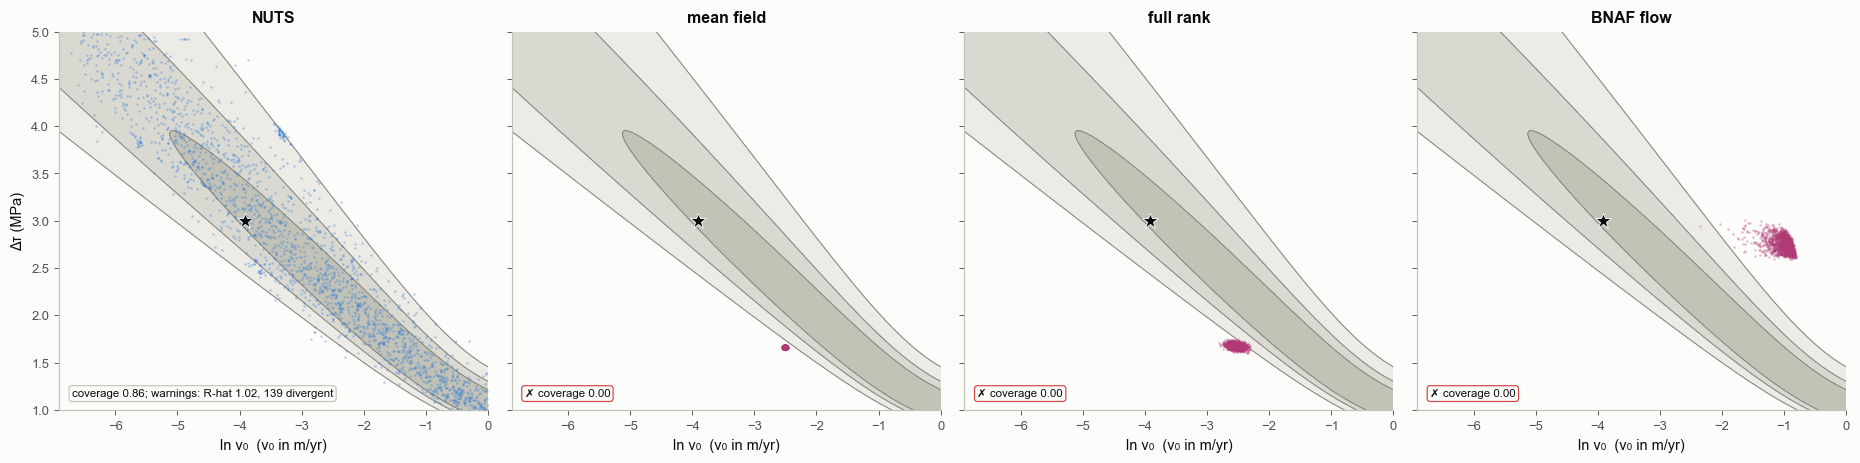

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.3), sharey=True)
for ax, mth in zip(axs, kn):
    BP.density(ax, g3)
    BP.samples(ax, kn[mth]["X"][:, 1:], NU if mth == "NUTS" else VI, n_max=2000, s=2.5, alpha=0.35)
    ax.plot(th_true[1], th_true[2], "*", color=S.INK, ms=11, mec=S.SURFACE, mew=0.6)
    ax.set_xlim(lo3[1], hi3[1]); ax.set_ylim(lo3[2], hi3[2])
    ax.set_xlabel("ln v₀  (v₀ in m/yr)")
    if mth == "NUTS":
        rh = max(D.rhat(kn["NUTS"]["Xc"][..., i]) for i in range(3))
        S.badge(ax, f"coverage {kn[mth]['score'][0]:.2f}; warnings: R-hat {rh:.2f}, {kn['NUTS']['div']} divergent",
                ok=None, loc="lower left", fs=7.5)
    else:
        S.badge(ax, f"coverage {kn[mth]['score'][0]:.2f}", ok=kn[mth]["score"][0] > 0.8, loc="lower left", fs=7.5)
    ax.set_title(mth, fontsize=10.5, fontweight="bold")
axs[0].set_ylabel("Δτ (MPa)")
fig.tight_layout()
bk.savefig(fig, "2-21_nonidentifiable")
plt.show()

**How to read it.** Grey: the exact $(\ln v_0, \Delta\tau)$ marginal, a ridge that runs from one side of the prior box
to the other. The data fix where the ridge is, not where along it the answer lies.
* The variational answers (printed means and widths) are narrow, each a small blob somewhere on or beside the ridge,
  with zero coverage of it. Mean field and full rank land at one place, BNAF at another. Even $\ln a\sigma$, which
  the data do constrain, is more than two exact standard deviations off for every variational family (compare the printed
  means with the exact row). None of them warns that the ridge exists.
* NUTS recovers most of the ridge (its coverage and widths are close to exact), and it still raises its hand: R-hat
  above 1.01 and many divergent transitions (printed, neutral badge). Here the sampler that struggled said so; the
  VI fits gave no comparable warning.
* The honest summary of these data is the ridge itself: $v_0\,e^{\Delta\tau/a\sigma}$ and $a\sigma$ are constrained,
  $v_0$ and Δτ separately are not. The fix is information (Δτ from a coseismic model, as in section 5, or later data
  when stress has relaxed), not a better optimiser.

## 7. Summary: when VI is worth it

| family | captures | misses | in this notebook |
|---|---|---|---|
| mean field | location; one scale per parameter | correlations (width shrinks to the conditional sd), curvature, other modes | section 4 formula; section 5 the narrowest |
| full rank | location, tilt | curvature, heavy tails, other modes | fits Gaussian shapes exactly |
| normalizing flow (IAF, BNAF) | bends, varying width; with enough flexibility, folds | modes it never visits during the fit; cost and tuning grow with flexibility | the only families that can bend, but each failed on one of the two bananas (sections 3, 5) |
| these families on a curved, bounded non-identifiable ridge | a narrow blob on or beside the ridge | the ridge | section 6 |

The last row is a result about these families, this objective and these optimisation runs, not about VI in
general: a full-rank Gaussian can represent a Gaussian posterior with a weakly constrained direction exactly. Here
the ridge is curved and cut off by the prior box, and the fits ended on narrow solutions.

**What VI is for.** VI turns inference into an optimisation with a fixed budget (steps × draws), which scales to many
parameters and to data streams where you must refit often. Its answer is the best member of a family that the
optimiser found, judged by a KL that tends to under-cover (2.28). Use it when a fast, possibly narrow answer is acceptable and you can check it
against a sampler on a smaller version of the problem, or as a fast initialiser for NUTS. The step after VI is
**amortised inference** (3.07): instead of optimising one $q$ for one data set, train a network that outputs $q$ for
*any* data set, so that a new event costs one network evaluation.

"Flow" also names a different tool: Shi, Ross & Yue (2026, p. 1) build posterior sampling "on
pretrained function-space flow-matching priors". There the flow is a learned *prior* over fields, and sampling is
still done by a Langevin-type method, not by fitting $q$. That use of flows is 3.07's topic.

**In practice.**
* For a slip model with hundreds of patches and a linear forward model, autodiff gradients are cheap and NUTS works
  (2.18). A full-rank Gaussian $q$ for 700 patches has the number of parameters printed below, and a mean-field $q$
  would shrink every trade-off between neighbouring patches to its conditional width (section 4).
* Stress-driven afterslip models depend on $v_0$, $\Delta\tau$ and $a\sigma$ through combinations like
  $v_0\,e^{\Delta\tau/a\sigma}$, the structure of sections 5-6. When all three are free, check for the ridge with a
  sampler or a grid before trusting any narrow error bar, whether it comes from VI or from an ensemble method
  (EnKI also uses only means and covariances; 2.24).

Next: [**2.22 · Gradients through physics: adjoints (optional)**](2-22_gradients_through_physics.ipynb).

In [16]:
T_k = 700
print(f"full-rank Gaussian for {T_k} patches: {T_k} means + {T_k * (T_k + 1) // 2} covariance entries; mean field: {2 * T_k} numbers")
print(f"notebook run time: {time.time() - T0:.0f} s")

full-rank Gaussian for 700 patches: 700 means + 245350 covariance entries; mean field: 1400 numbers
notebook run time: 58 s
